In [1]:
import sys
sys.path.append('../scripts')
from utils.cftp_func import *

# Test multiple mcmc (one run)

In [7]:
# Define parameters & model
N = 1000
d = 4
beta = 0.1
maxiter = 10**6
#G, couplings = create_ER_graph(N, d, coupling_type='gauss')
G, couplings, N = create_lattice_graph(50, 2, model='RL_sg', periodic=True)
#G, couplings = create_complete_graph(N, model='CW')

max_degree = max(d for _, d in G.degree())
beta_SG = np.arctanh(np.sqrt(1/d))
beta_uni = np.arctanh(1/(d-1))
beta_dob = np.arctanh(1/d)
beta_uni, beta_SG, max_degree, beta_dob, N

(np.float64(0.34657359027997264),
 np.float64(0.5493061443340548),
 4,
 np.float64(0.25541281188299536),
 2500)

In [10]:
# Run BC forward
nb_star_state, final_step = multiple_mcmc(beta, G, couplings, sampler=F_beta_Glauber, max_iter=maxiter, n_configs=10, lazy=False)

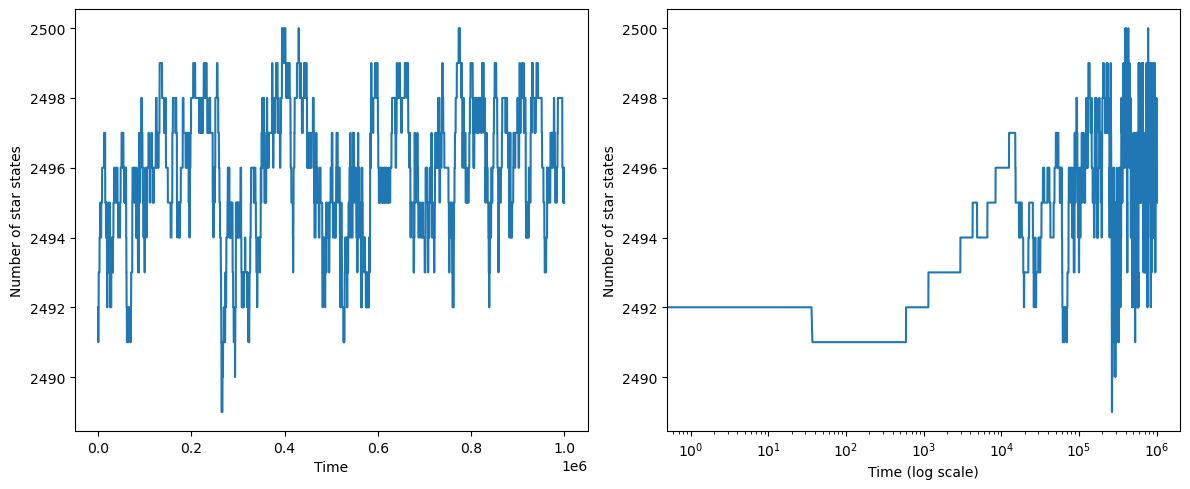

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot(nb_star_state)
ax1.set_xlabel('Time')
ax1.set_ylabel('Number of star states')

ax2.plot(nb_star_state)
ax2.set_xscale('log')
ax2.set_xlabel('Time (log scale)')
ax2.set_ylabel('Number of star states')

plt.tight_layout()
plt.show()

# Coalescence times

In [5]:
d = 4
beta_SG = np.arctanh(np.sqrt(1/d))
beta_uni = np.arctanh(1/d)
beta_uni, beta_SG

(np.float64(0.25541281188299536), np.float64(0.5493061443340548))

In [ ]:
beta = 0.3
coup_type = 'gauss'
G_builder = lambda N: create_ER_graph(N, d=4, coupling_type=coup_type)
nb_runs = 3    
nb_itermax = 10**7
N_list = [100, 250, 500, 1000, 2500, 5000]
csv_path = f"../results/tmp/coal_time_DS_ER_{coup_type}_d{d}.csv"

In [7]:
df = compute_coal_time_DS(N_list, beta, G_builder, n_runs=nb_runs, sampler=F_beta_Glauber, max_iter=nb_itermax, n_configs=100, lazy=False)

N=100
N=250


SystemError: CPUDispatcher(<function _multiple_mcmc_numba_core at 0x718e6fc6fe20>) returned a result with an exception set

In [ ]:
if os.path.exists(csv_path):
    df_full = pd.read_csv(csv_path)
    df_combined = pd.concat([df_full, df], ignore_index=True)
    df_combined.to_csv(csv_path, index=False)
else:
    df.to_csv(csv_path, index=False)

In [ ]:
df = pd.read_csv(csv_path)

print(df['beta'].unique())
print(df['sampler'].unique())
print(df['lazy'].unique())
print(df['init_mode'].unique())
print(df['n_runs'].unique())
print(df['max_iter'].unique())
print(df['N'].unique())
print(len(df))  # total number of rows

df

In [ ]:
mask = (
    (df['sampler'] == 'F_beta_Glauber') &
    (df['lazy'] == False) &
    (df['init_mode'] == 'full_star') & 
    (df['n_coal'] == df['n_runs'])
)
df_filtered = df[mask]

betas_to_exclude = []
for beta in df_filtered['beta'].unique():
    if beta in betas_to_exclude:
        continue    
    sub_df = df_filtered[df_filtered['beta'] == beta]
    plt.errorbar(sub_df['N'], sub_df['mean_coal_time'],
                yerr=sub_df['std_coal_time'],
                label=f'beta={beta:.2f}',
                capsize=3)

plt.xlabel('N')
plt.ylabel('Mean coalescence time')
plt.xscale('log')
plt.yscale('log')
plt.legend()
plt.show()

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
scalings = {
    r'$T / N$': (lambda N, T: T / N, 
                 lambda N, T, sT: sT / N),
    r'$T / (N \ln N)$': (lambda N, T: T / (N * np.log(N)), 
                          lambda N, T, sT: sT / (N * np.log(N))),
    r'$T / N^2$': (lambda N, T: T / N**2, 
                   lambda N, T, sT: sT / N**2),
}

for ax, (label, (scaling_fn, err_fn)) in zip(axes, scalings.items()):
    for beta in df_filtered['beta'].unique():
        sub_df = df_filtered[df_filtered['beta'] == beta].sort_values('N')
        N = sub_df['N'].values
        T = sub_df['mean_coal_time'].values
        sT = sub_df['std_coal_time'].values
        ax.errorbar(N, scaling_fn(N, T), yerr=err_fn(N, T, sT),
                    label=f'beta={beta:.2f}', capsize=3)
    ax.set_xlabel('N')
    ax.set_ylabel(label)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [ ]:
N_to_exclude = [5000]
for N in df_filtered['N'].unique():
    if N in N_to_exclude:
        continue    
    sub_df = df_filtered[df_filtered['N'] == N].sort_values('beta')
    k = sub_df['n_coal'].values
    n = sub_df['n_runs'].values
    p, err_down, err_up = wilson_interval(k, n)
    plt.errorbar(sub_df['beta'], p,
                 yerr=[err_down, err_up],
                 label=f'N={N}', capsize=3)

plt.xlabel(r'$\beta$')
plt.ylabel('Fraction of runs coalesced')
plt.legend()
plt.show()

# Evolution star states

In [ ]:
d = 4
beta_SG = np.arctanh(np.sqrt(1/d))
beta_uni = np.arctanh(1/d)
beta_uni, beta_SG

In [ ]:
N = 5000
beta_list = [0.2, 0.22, 0.23, 0.24, 0.25, 0.26, 0.27]
#beta_list = [0.3, 0.31, 0.32, 0.33, 0.34]
coup_type = 'ising'
G_builder = lambda N: create_ER_graph(N, d=4, coupling_type=coup_type)
nb_runs = 10    
nb_itermax = 10**7

In [ ]:
dfs = []
for beta in beta_list:
    print(f"beta={beta}")
    df_beta = compute_nb_star(N, beta, G_builder, n_runs=nb_runs, sampler=F_beta_Glauber, max_iter=nb_itermax, init_mode='full_star', lazy=False, n_points=10000)
    dfs.append(df_beta)

df = pd.concat(dfs, ignore_index=True)

csv_path = f"../results/tmp/nb_star_ER_{coup_type}_d{d}_N{N}.csv"
df.to_csv(csv_path, index=False)


In [ ]:
df = pd.read_csv(csv_path)
for beta in df['beta'].unique():
    sub_df = df[df['beta'] == beta].sort_values('time')
    plt.plot(sub_df['time'], sub_df['mean_nb_star'], label=f'beta={beta:.2f}')
    plt.fill_between(sub_df['time'],
                     sub_df['mean_nb_star'] - sub_df['std_nb_star'],
                     sub_df['mean_nb_star'] + sub_df['std_nb_star'],
                     alpha=0.3)
plt.xscale('log')
plt.xlabel('Time')
plt.ylabel('Mean number of star states')
plt.legend()
plt.show()

In [ ]:
beta = 0.23
sub_df = df[df['beta'] == beta].sort_values('time')
N = sub_df['N'].values[0]

t_over_N = sub_df['time'].values / N
log_W_over_N = np.log(sub_df['mean_nb_star'].values / N)

from scipy.stats import linregress

mask = (t_over_N > 10)  & (log_W_over_N > -np.inf) & np.isfinite(log_W_over_N)
slope, intercept, r, p, se = linregress(t_over_N[mask], log_W_over_N[mask])
C = -slope
print(f"C = {C:.3f}, R²={r**2:.4f}")

plt.plot(t_over_N, log_W_over_N, label=f'data beta={beta:.2f}')
plt.plot(t_over_N[mask], intercept + slope * t_over_N[mask], '--', label=f'fit C={C:.3f}')
plt.xlabel(r'$t/N$')
plt.ylabel(r'$\log(W/N)$')
plt.legend()
plt.show()

In [ ]:
for beta in [0.2, 0.22]:
    for N in [1000, 2000, 5000]:
        csv_path = f"../results/tmp/nb_star_ER_{coup_type}_d{d}_N{N}.csv"
        df = pd.read_csv(csv_path)
        sub_df = df[(df['beta'] == beta) & (df['N'] == N)].sort_values('time')
        t_over_N = sub_df['time'].values / N
        log_W_over_N = np.log(sub_df['mean_nb_star'].values / N)
        plt.plot(t_over_N, log_W_over_N, label=f'beta={beta:.2f}, N={N}')

plt.xlabel(r'$t/N$')
plt.ylabel(r'$\log(W/N)$')
plt.legend(fontsize=8)
plt.show()